# ODIR-5K ensemble: per-disease analysis and Grad-CAM

This notebook trains nothing. It reads what `odir_efficientnet_cv5.ipynb` saved in `outputs_cv/` (`odir_effnetb0_cv_ensemble.pt` and `cv_ensemble_test_predictions.csv`) and answers three questions about the **test set**:
1. **Which diseases does the ensemble catch, and which does it miss?** It reports sensitivity for each disease group, with 95% confidence intervals, at threshold 0.5 and at the 85%-sensitivity threshold.
2. **Where does it look?** Ensemble Grad-CAM maps for each main disease.
3. **What do its worst mistakes look like?** The most confident missed diseases and the most confident false alarms.

**Run it** in the same folder as the cross-validation run, so `outputs_cv/` is next to the notebook. It takes a few minutes on the V100:
```bash
jupyter nbconvert --to notebook --execute odir_cv_analysis.ipynb --output analysis_run.ipynb \
    --ExecutePreprocessor.kernel_name=odir-env
```
Everything is also saved to `outputs_cv/analysis/`.

In [1]:
import os, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.transforms as T
from torchvision.models import efficientnet_b0
from sklearn.metrics import roc_auc_score
import warnings; warnings.filterwarnings('ignore')

OUT_DIR = Path('/kaggle/working') if Path('/kaggle/working/odir_effnetb0_cv_ensemble.pt').exists() else Path('outputs_cv')
ANALYSIS_DIR = OUT_DIR / 'analysis'; ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

ckpt = torch.load(OUT_DIR / 'odir_effnetb0_cv_ensemble.pt', map_location=device)
IMG_SIZE, THR, CLASS_NAMES = ckpt['img_size'], ckpt['thresholds'], ckpt['class_names']
SCREEN = next(k for k in THR if 'sens' in k)            # e.g. '85% sens'
models = []
for sd in ckpt['state_dicts']:
    m = efficientnet_b0(weights=None)
    m.classifier = nn.Sequential(nn.Dropout(p=ckpt.get('dropout', 0.5)), nn.Linear(1280, 2))
    m.load_state_dict(sd); models.append(m.to(device).eval())

preds = pd.read_csv(OUT_DIR / 'cv_ensemble_test_predictions.csv')
preds['keywords'] = preds['keywords'].fillna('')
missing = (~preds['file_path'].map(os.path.exists)).sum()
assert missing == 0, f'{missing} test images not found - run this on the machine that ran the CV notebook'
print(f'{len(models)} models | image size {IMG_SIZE} | device {device}')
print('thresholds:', {k: round(v, 3) for k, v in THR.items()})
print(f'{len(preds)} test images, {preds.ID.nunique()} patients, {preds.target.mean():.1%} abnormal')

5 models | image size 512 | device cuda
thresholds: {'0.5': 0.5, 'Youden': 0.474, '85% sens': 0.29}
1281 test images, 671 patients, 55.6% abnormal


## 1. Sensitivity per disease group

The disease groups follow ODIR's categories, using each eye's own keywords. An image with several diseases counts in each of its groups. **Other** means abnormal eyes that match none of the six named groups, for example epiretinal membrane, drusen, laser spots or myelinated nerve fibres.

- **Sensitivity** is the share of that group's eyes flagged as abnormal. The 95% interval is a Wilson interval.
- **AUC vs normal** is how well the ensemble separates that group's eyes from **all normal test eyes**, independent of any threshold.

In [2]:
GROUPS = {   # name -> regex on the eye's keywords (None = "Other")
    'Diabetic retinopathy (D)':     r'proliferative|diabetic retinopathy',
    '   DR: mild NPDR':             r'mild non ?proliferative',
    '   DR: moderate NPDR':         r'moderate non ?proliferative',
    '   DR: severe NPDR':           r'severe non ?proliferative',
    '   DR: proliferative':         r'(^|, )proliferative',
    'Glaucoma (G)':                 r'glaucoma',
    '   suspected glaucoma':        r'suspected glaucoma',
    'Cataract (C)':                 r'cataract',
    'AMD (A)':                      r'age-related macular degeneration',
    'Hypertensive retinopathy (H)': r'hypertensive retinopathy',
    'Myopia (M)':                   r'myopi',
    'Other (O)':                    None,
}
MAIN = [g for g in GROUPS if not g.startswith(' ') and GROUPS[g]]

def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p, d = k / n, 1 + z * z / n
    c, h = (p + z * z / (2 * n)) / d, z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

def fmt(k, n):
    lo, hi = wilson(k, n)
    return f'{k / n:.1%} ({lo:.0%}-{hi:.0%})' if n else '-'

abn, nor = preds[preds.target == 1], preds[preds.target == 0]
in_main = np.zeros(len(abn), bool)
for g in MAIN:
    in_main |= abn['keywords'].str.contains(GROUPS[g], regex=True).values

rows = []
for g, rx in GROUPS.items():
    sub = abn[~in_main] if rx is None else abn[abn['keywords'].str.contains(rx, regex=True)]
    n = len(sub)
    row = {'group': g, 'images': n, 'patients': sub.ID.nunique(),
           'mean P(abnormal)': round(sub.prob_abnormal.mean(), 3) if n else np.nan,
           'AUC vs normal': round(roc_auc_score(np.r_[np.zeros(len(nor)), np.ones(n)],
                                                np.r_[nor.prob_abnormal, sub.prob_abnormal]), 3) if n else np.nan}
    for rule in ('0.5', SCREEN):
        k = int((sub.prob_abnormal >= THR[rule]).sum())
        row[f'sensitivity @ {rule}'] = fmt(k, n)
        row[f'_sens_{rule}'] = k / n if n else np.nan
        row[f'_ci_{rule}'] = wilson(k, n)
    rows.append(row)
disease = pd.DataFrame(rows)

spec = {rule: fmt(int((nor.prob_abnormal < THR[rule]).sum()), len(nor)) for rule in ('0.5', SCREEN)}
print(f'Normal eyes: {len(nor)} | specificity @ 0.5: {spec["0.5"]} | specificity @ {SCREEN}: {spec[SCREEN]}')
show_cols = ['group', 'images', 'patients', 'mean P(abnormal)', 'AUC vs normal', 'sensitivity @ 0.5', f'sensitivity @ {SCREEN}']
disease[show_cols].to_csv(ANALYSIS_DIR / 'per_disease_sensitivity.csv', index=False)
display(disease[show_cols].style.hide(axis='index'))

Normal eyes: 569 | specificity @ 0.5: 85.4% (82%-88%) | specificity @ 85% sens: 65.0% (61%-69%)


group,images,patients,mean P(abnormal),AUC vs normal,sensitivity @ 0.5,sensitivity @ 85% sens
Diabetic retinopathy (D),355,217,0.722000,0.879000,74.4% (70%-79%),86.5% (83%-90%)
DR: mild NPDR,97,82,0.532000,0.749000,49.5% (40%-59%),70.1% (60%-78%)
DR: moderate NPDR,211,136,0.773000,0.919000,81.5% (76%-86%),91.9% (87%-95%)
DR: severe NPDR,35,23,0.908000,0.982000,97.1% (85%-99%),97.1% (85%-99%)
DR: proliferative,0,0,nan,nan,-,-
Glaucoma (G),67,43,0.526000,0.778000,49.3% (38%-61%),79.1% (68%-87%)
suspected glaucoma,7,7,0.427000,0.645000,42.9% (16%-75%),57.1% (25%-84%)
Cataract (C),60,44,0.843000,0.939000,86.7% (76%-93%),90.0% (80%-95%)
AMD (A),44,27,0.752000,0.916000,81.8% (68%-90%),93.2% (82%-98%)
Hypertensive retinopathy (H),34,18,0.602000,0.842000,47.1% (31%-63%),82.4% (66%-92%)


In [3]:
# Which individual keywords are hardest? (terms with at least 15 test eyes)
terms = abn.assign(term=abn['keywords'].str.split(', ')).explode('term')
terms = terms[~terms.term.isin(['lens dust', 'image offset', 'optic disk photographically invisible', ''])]
kw = (terms.groupby('term')
           .agg(images=('prob_abnormal', 'size'), mean_prob=('prob_abnormal', 'mean'),
                caught=('prob_abnormal', lambda p: (p >= THR[SCREEN]).mean()))
           .query('images >= 15').sort_values('caught'))
kw['mean_prob'] = kw['mean_prob'].round(3); kw['caught'] = (kw['caught'] * 100).round(1).astype(str) + '%'
kw = kw.rename(columns={'caught': f'sensitivity @ {SCREEN}'})
kw.to_csv(ANALYSIS_DIR / 'per_keyword_sensitivity.csv')
print('Keywords sorted from hardest to easiest:')
display(kw)

Keywords sorted from hardest to easiest:


,images,mean_prob,sensitivity @ 85% sens
term,,,
myelinated nerve fibers,23,0.552,69.6%
mild nonproliferative retinopathy,99,0.536,70.7%
glaucoma,60,0.538,81.7%
hypertensive retinopathy,34,0.602,82.4%
drusen,26,0.494,88.5%
cataract,60,0.843,90.0%
pathological myopia,52,0.833,90.4%
dry age-related macular degeneration,35,0.722,91.4%
moderate non proliferative retinopathy,211,0.773,91.9%


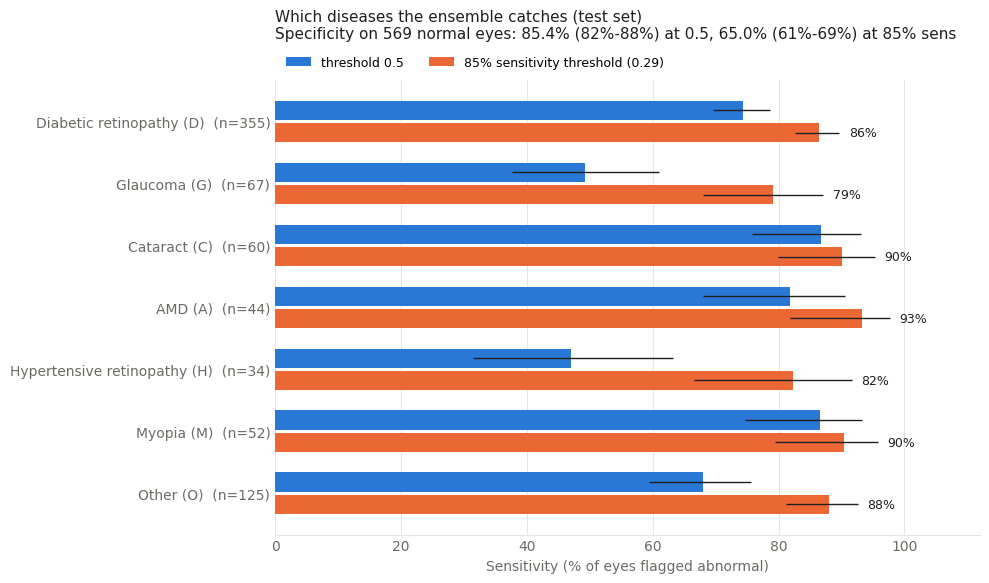

In [4]:
# Sensitivity per disease group at the two thresholds (95% Wilson intervals)
C_DEFAULT, C_SCREEN = '#2a78d6', '#eb6834'          # categorical slots 1 and 2
INK, MUTED, GRID = '#1f1f1e', '#6b6a64', '#e6e5e0'

plot_df = disease[[not g.startswith(' ') and n > 0 for g, n in zip(disease.group, disease.images)]].iloc[::-1].reset_index(drop=True)
y = np.arange(len(plot_df)); h = 0.36
fig, ax = plt.subplots(figsize=(10, 0.62 * len(plot_df) + 1.6))
for off, rule, color, label in [(h / 2, '0.5', C_DEFAULT, 'threshold 0.5'),
                                (-h / 2, SCREEN, C_SCREEN, f'{SCREEN}itivity threshold ({THR[SCREEN]:.2f})')]:
    vals = plot_df[f'_sens_{rule}'].values * 100
    lo = np.array([c[0] for c in plot_df[f'_ci_{rule}']]) * 100; hi = np.array([c[1] for c in plot_df[f'_ci_{rule}']]) * 100
    ax.barh(y + off, vals, height=h * 0.86, color=color, label=label, zorder=2)
    xerr = np.clip([vals - lo, hi - vals], 0, None)      # rounding can make a 0/100% interval edge slightly negative
    ax.errorbar(vals, y + off, xerr=xerr, fmt='none', ecolor=INK, elinewidth=1, capsize=0, zorder=3)
    if rule == SCREEN:
        for yi, v, top in zip(y + off, vals, hi):
            ax.text(max(v, top) + 1.5, yi, f'{v:.0f}%', va='center', fontsize=9, color=INK)
ax.set_yticks(y, [f'{g}  (n={n})' for g, n in zip(plot_df.group, plot_df.images)], fontsize=10, color=INK)
ax.set_xlim(0, 112); ax.set_xlabel('Sensitivity (% of eyes flagged abnormal)', color=MUTED)
ax.xaxis.grid(True, color=GRID, zorder=0); ax.set_axisbelow(True)
for s in ('top', 'right', 'left'): ax.spines[s].set_visible(False)
ax.spines['bottom'].set_color(GRID); ax.tick_params(colors=MUTED, length=0)
ax.set_title(f'Which diseases the ensemble catches (test set)\n'
             f'Specificity on {len(nor)} normal eyes: {spec["0.5"]} at 0.5, {spec[SCREEN]} at {SCREEN}',
             loc='left', fontsize=11, color=INK, pad=30)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(ANALYSIS_DIR / 'sensitivity_by_disease.png', dpi=150); plt.show()

## 2. Ensemble Grad-CAM by disease

For each main disease, the notebook shows one eye that was **correctly flagged**: the one with the median confidence among the correctly flagged eyes, so it isn't cherry-picked. Each model's Grad-CAM targets the log-odds of *Abnormal vs Normal*. The five maps are averaged and then rescaled to 0–1.

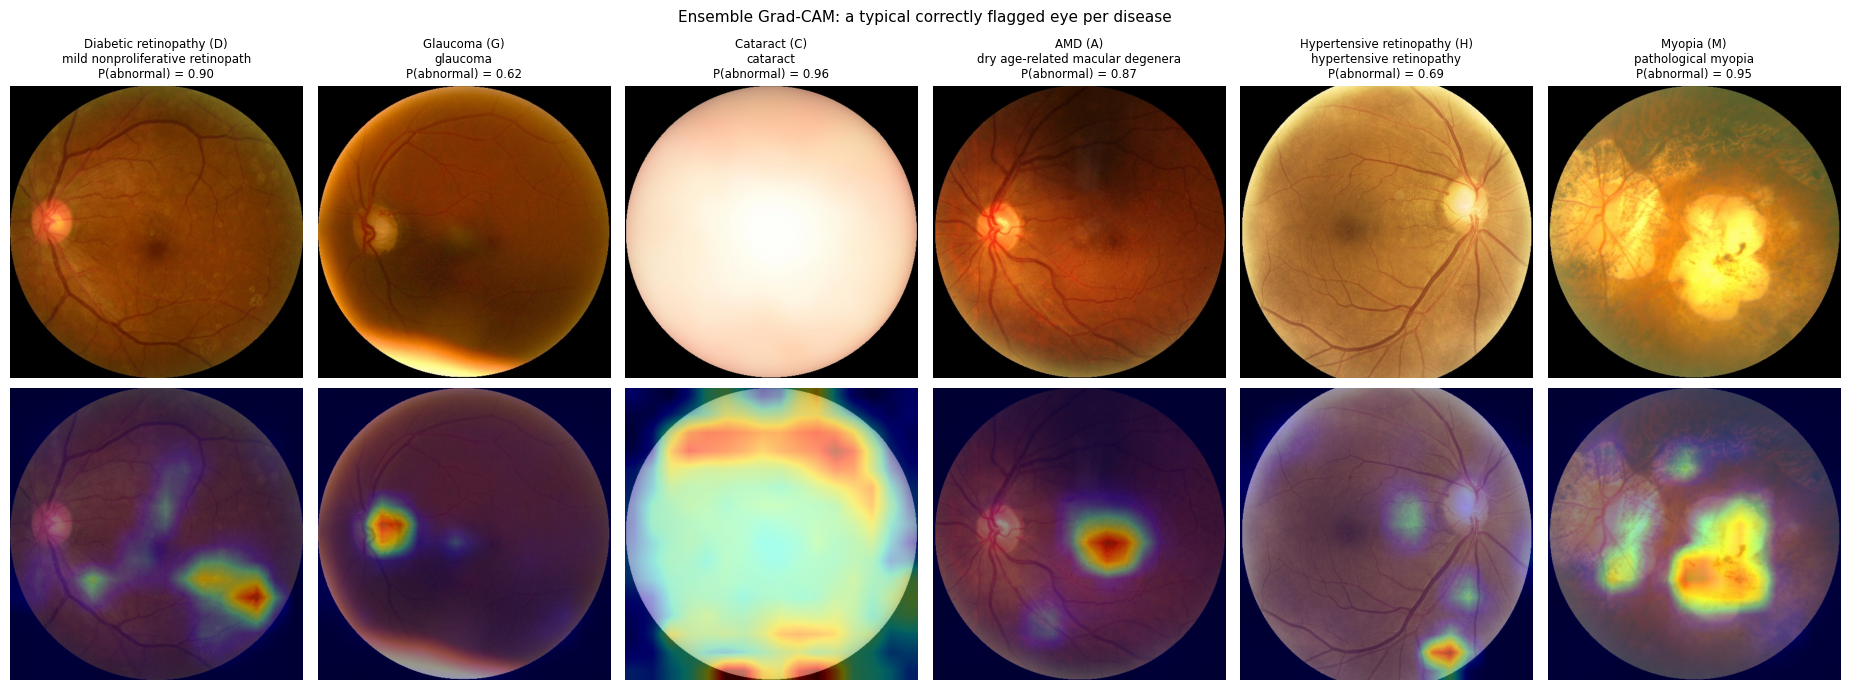

In [5]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
eval_tfms = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])

def denorm(t):
    return (t.permute(1, 2, 0).cpu().numpy() * STD + MEAN).clip(0, 1)

def ensemble_gradcam(x):
    """Average Grad-CAM over all fold models for a batch x; returns maps in [0, 1]."""
    total = torch.zeros(x.size(0), *x.shape[-2:], device=x.device)
    for m in models:
        store = {}
        def hook(module, inp, out):
            store['a'] = out; out.register_hook(lambda g: store.__setitem__('g', g))
        handle = m.features[-1].register_forward_hook(hook)
        with torch.enable_grad():
            logits = m(x); m.zero_grad(set_to_none=True)
            (logits[:, 1] - logits[:, 0]).sum().backward()
        handle.remove()
        cam = F.relu((store['g'].mean((2, 3), keepdim=True) * store['a']).sum(1, keepdim=True))
        total += F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[:, 0].detach()
    total -= total.amin((1, 2), keepdim=True)
    return (total / (total.amax((1, 2), keepdim=True) + 1e-8)).cpu().numpy()

def cam_grid(df, titles, path, suptitle):
    x = torch.stack([eval_tfms(Image.open(p).convert('RGB')) for p in df.file_path]).to(device)
    cams = ensemble_gradcam(x)
    fig, axes = plt.subplots(2, len(df), figsize=(3.1 * len(df), 7.2), squeeze=False)
    for i, t in enumerate(titles):
        img = denorm(x[i])
        axes[0, i].imshow(img); axes[0, i].set_title(t, fontsize=8.5)
        axes[1, i].imshow(img); axes[1, i].imshow(cams[i], cmap='jet', alpha=0.4)
    for a in axes.ravel(): a.axis('off')
    plt.suptitle(suptitle, fontsize=11); plt.tight_layout(); plt.savefig(path, dpi=130); plt.show()

picks, titles = [], []
for g in MAIN:
    hit = abn[abn['keywords'].str.contains(GROUPS[g], regex=True) & (abn.prob_abnormal >= THR[SCREEN])]
    if len(hit):
        r = hit.iloc[(hit.prob_abnormal - hit.prob_abnormal.median()).abs().argsort().iloc[0]]
        picks.append(r); titles.append(f"{g}\n{r['keywords'][:32]}\nP(abnormal) = {r.prob_abnormal:.2f}")
if picks:
    cam_grid(pd.DataFrame(picks), titles, ANALYSIS_DIR / 'gradcam_by_disease.png',
             'Ensemble Grad-CAM: a typical correctly flagged eye per disease')

## 3. Most confident mistakes

- **Missed disease:** abnormal eyes with the *lowest* P(abnormal).
- **False alarms:** normal eyes with the *highest* P(abnormal).

The labels come from free-text keywords, so some "mistakes" may be label noise or poor-quality photos rather than model errors.

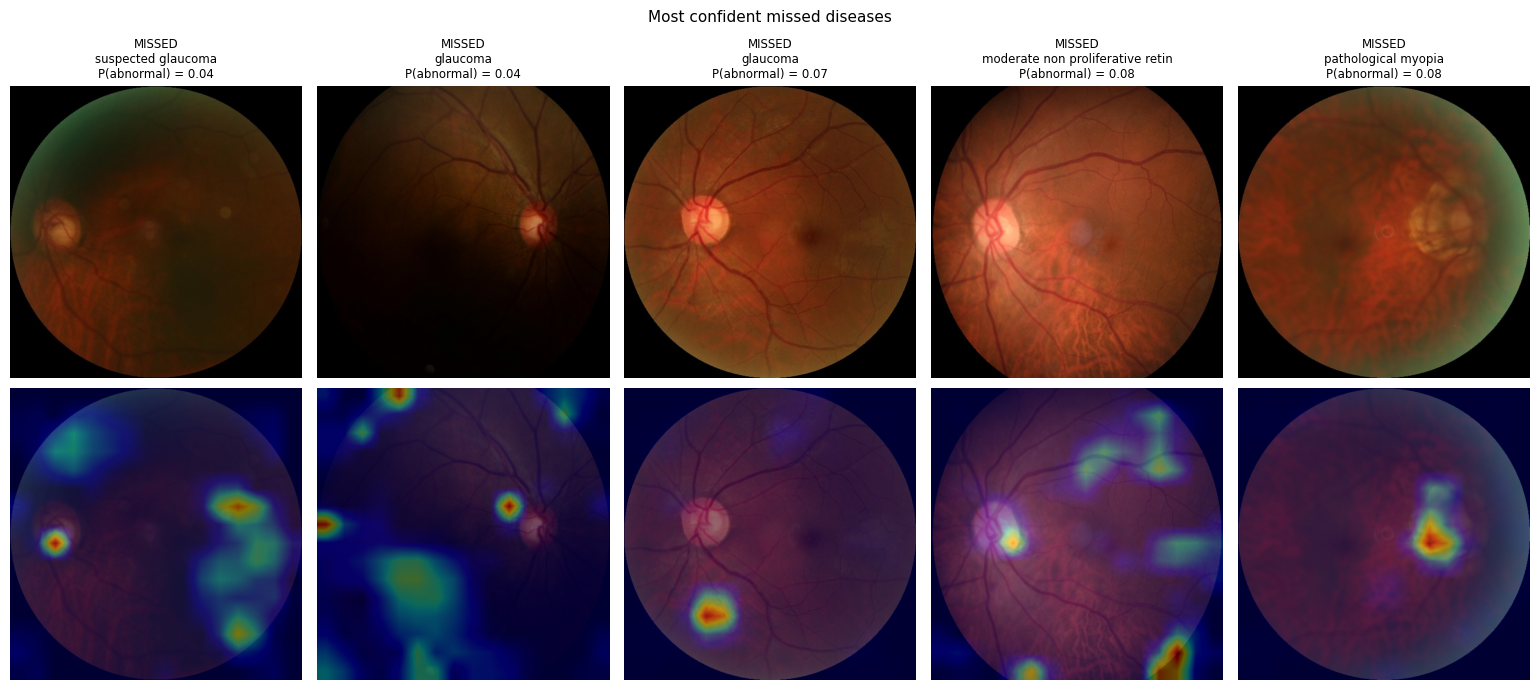

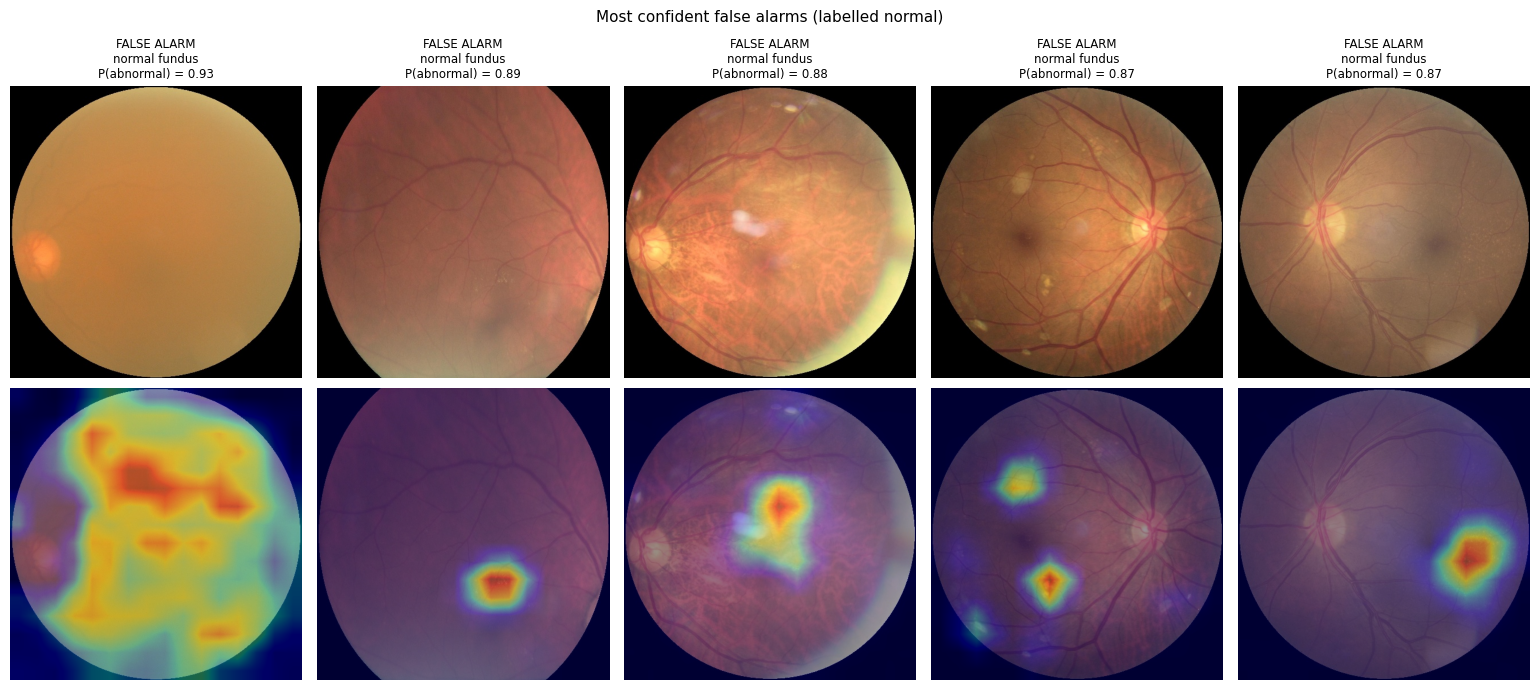

At the 85% sens threshold: 95 missed abnormal eyes, 199 false alarms on normal eyes
Missed eyes by group:
  Diabetic retinopathy (D)         48 of 355
  Glaucoma (G)                     14 of 67
  Cataract (C)                      6 of 60
  AMD (A)                           3 of 44
  Hypertensive retinopathy (H)      6 of 34
  Myopia (M)                        5 of 52
  Other (O)                        15 of 125

Saved: ['false_alarm_gradcam.png', 'gradcam_by_disease.png', 'missed_disease_gradcam.png', 'per_disease_sensitivity.csv', 'per_keyword_sensitivity.csv', 'sensitivity_by_disease.png']


In [6]:
fn = abn.nsmallest(5, 'prob_abnormal'); fp = nor.nlargest(5, 'prob_abnormal')
cam_grid(fn, [f"MISSED\n{r['keywords'][:32]}\nP(abnormal) = {r.prob_abnormal:.2f}" for _, r in fn.iterrows()],
         ANALYSIS_DIR / 'missed_disease_gradcam.png', 'Most confident missed diseases')
cam_grid(fp, [f"FALSE ALARM\n{r['keywords'][:32]}\nP(abnormal) = {r.prob_abnormal:.2f}" for _, r in fp.iterrows()],
         ANALYSIS_DIR / 'false_alarm_gradcam.png', 'Most confident false alarms (labelled normal)')

n_fn = int((abn.prob_abnormal < THR[SCREEN]).sum()); n_fp = int((nor.prob_abnormal >= THR[SCREEN]).sum())
print(f'At the {SCREEN} threshold: {n_fn} missed abnormal eyes, {n_fp} false alarms on normal eyes')
print('Missed eyes by group:')
for g in MAIN:
    sub = abn[abn['keywords'].str.contains(GROUPS[g], regex=True)]
    print(f'  {g:30s} {int((sub.prob_abnormal < THR[SCREEN]).sum()):4d} of {len(sub)}')
other = abn[~in_main]
print(f'  {"Other (O)":30s} {int((other.prob_abnormal < THR[SCREEN]).sum()):4d} of {len(other)}')
print('\nSaved:', sorted(p.name for p in ANALYSIS_DIR.iterdir()))